# Previsão de preços de casas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

In [2]:
dados = fetch_california_housing(as_frame=True)
df = dados.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


-->fetch_california_housing(...) descarrega o dataset (dados do censo de 1990 da Califórnia). O as_frame=True pede que os dados venham organizados como tabela do pandas (biblioteca).
-->dados é um objeto que guarda várias coisas (os dados, descrições, nomes das colunas). dados.frame é a tabela completa, e guardámo-la numa variável chamada df. Uma variável é só um nome que aponta para um valor.
-->df é um DataFrame: uma tabela com linhas e colunas. Aqui, cada linha é um bairro e cada coluna é uma característica.
-->.head() mostra as 5 primeiras linhas, só para espreitares como os dados são.


In [3]:
df.shape

(20640, 9)

df.shape devolve (20640, 9): 20 640 linhas (bairros) e 9 colunas (8 features mais o alvo).

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


df.info() lista cada coluna com o número de valores preenchidos e o tipo de dados. Se alguma tivesse menos, haveria valores em falta.

In [5]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


df.describe() devolve estatísticas de cada coluna. Por exemplo, em AveRooms o máximo é cerca de 142, o que não faz sentido para uma casa normal. São os outliers, valores extremos que podem distorcer um modelo.

In [6]:
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


df.isnull().sum() conta quantos valores em falta há em cada coluna.

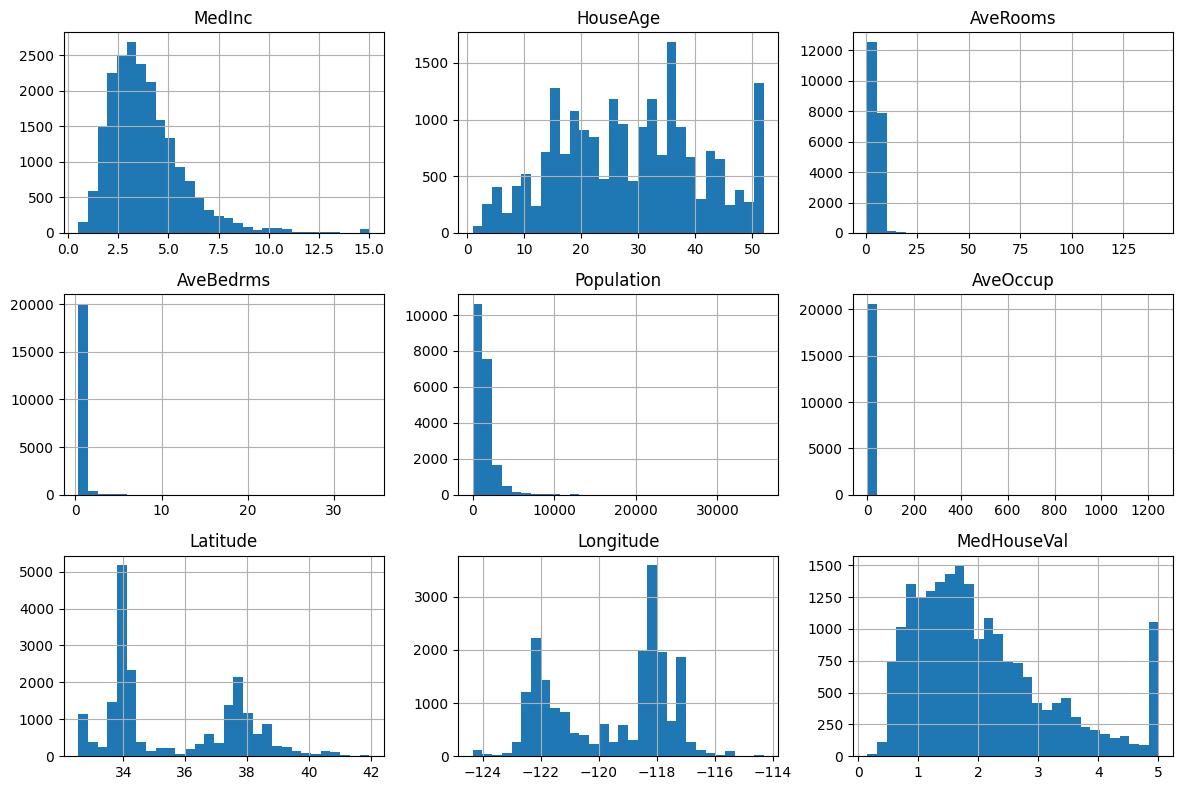

In [7]:
df.hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

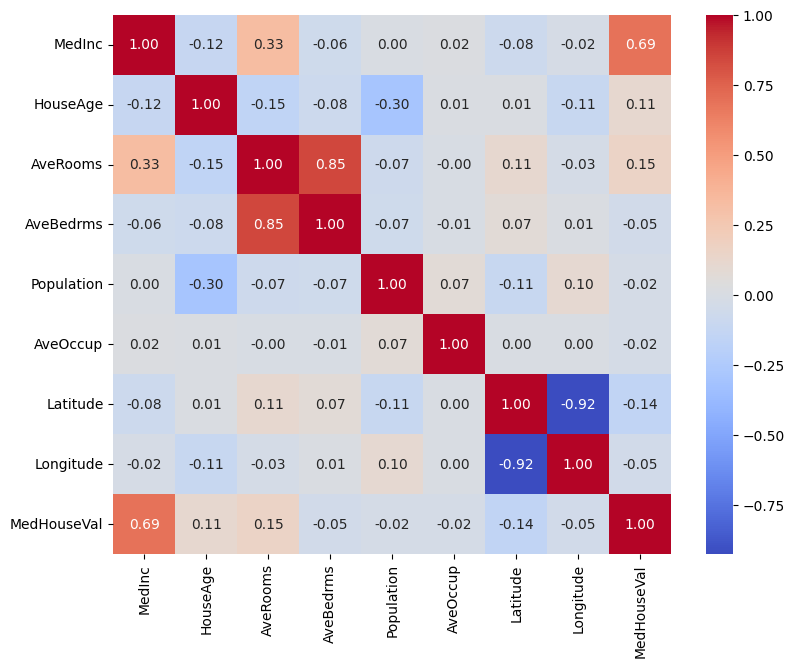

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

A correlção mede a releção que existe entre duas variáveis entre -1 e 1. Perto de 1 significa que quando uma sobe a outra também sobe (diretamente proporcionais). Perto de -1 significa que quando uma sobe a outra desce (inversamente proporcionais). Perto de 0 significa que não há uma relação linear clara.

Na linha MedHouseVal é o que mais se relaciona com o preço. O MedInc (rendimento mediano) tem a correlação mais forte, perto de 0.69, o que faz sentido pois bairros com rendimentos mais altos têm casas mais caras. É uma pista de que essa variável vai ser muito importante para o modelo.

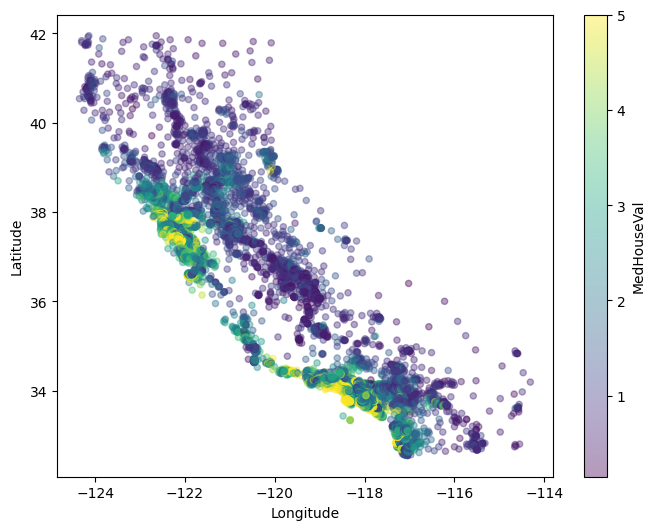

In [9]:
df.plot(kind="scatter", x="Longitude", y="Latitude",
        c="MedHouseVal", cmap="viridis", alpha=0.4, figsize=(8, 6))
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_treino.shape, X_teste.shape)

(16512, 8) (4128, 8)


O X fica com todas as colunas menos o preço, ou seja, as features. Por convenção usa-se X maiúsculo para as entradas.
O y fica só com a coluna do preço, o alvo.
O train_test_split baralha os dados e divide-os, o test_size=0,2 reserva 20% para teste e os outro 80% ficam para treinar.
O random_state fixa o baralhar, sem isto cada execução daria uma divisão diferente e os resultados mudariam.


In [11]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()
modelo.fit(X_treino, y_treino)

LinearRegression()

É criado um modelo ainda "vazio", sem ter aprendido nada. O .fit é o treino, o modelo olha para os exemplos (features e preço correto) e ajusta os pesos.

In [12]:
previsoes = modelo.predict(X_teste)

O .predict() recebe as features dos bairros de teste (sem os preços) e devolve o preço que o modelo acha que cada um tem.

In [13]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_teste, previsoes)
r2 = r2_score(y_teste, previsoes)

print(f"MAE: {mae:.3f}")
print(f"R²: {r2:.3f}")

MAE: 0.533
R²: 0.576


MAE (erro absoluto médio): a diferença média, em valor absoluto, entre o preço previsto e o real. Como o preço está em centenas de milhares de dólares, um MAE de 0.53 significa um erro médio de cerca de 53 000 $. Quanto mais baixo, melhor.
R²: indica quanto da variação dos preços o modelo consegue explicar. Vale 1 se previsse tudo na perfeição e 0 se fosse tão bom como prever sempre o preço médio. Quanto mais perto de 1, melhor.


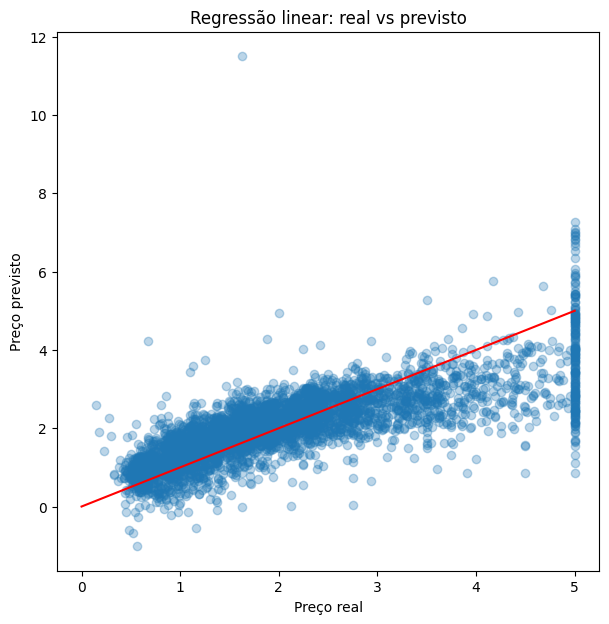

In [14]:
plt.figure(figsize=(7, 7))
plt.scatter(y_teste, previsoes, alpha=0.3)
plt.plot([0, 5], [0, 5], color="red")
plt.xlabel("Preço real")
plt.ylabel("Preço previsto")
plt.title("Regressão linear: real vs previsto")
plt.show()

Cada ponto é um bairro de teste. A linha vermelha representa a previsão perfeita (previsto = real), por isso quanto mais perto dela estiverem os pontos, melhor o modelo.

In [15]:
pesos = pd.Series(modelo.coef_, index=X.columns).sort_values()
print(pesos)

Longitude    -0.433708
Latitude     -0.419792
AveRooms     -0.123323
AveOccup     -0.003526
Population   -0.000002
HouseAge      0.009724
MedInc        0.448675
AveBedrms     0.783145
dtype: float64


Mostra o peso que o modelo atribuiu a cada feature. Um peso positivo significa que, quando essa feature sobe, o preço previsto sobe, e um peso negativo o contrário. É preciso ter cuidado com a comparação de valores, cada variável tem escalas diferentes.